In [1]:
%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

Note: you may need to restart the kernel to use updated packages.


In [2]:
#import and install all the needed libraries
%pip install pandas numpy scipy matplotlib seaborn statsmodels scikit-learn
import pandas as pd
import numpy as np
import os
import scipy
import sklearn
import statsmodels
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

print(pd.__version__, np.__version__, scipy.__version__, sklearn.__version__, statsmodels.__version__)

Note: you may need to restart the kernel to use updated packages.
2.2.3 2.1.3 1.15.3 1.6.1 0.14.4


In [3]:
df = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Part 1: Data Loading & EDA**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.duplicated().sum() 
df[df.duplicated()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [7]:
df['TotalCharges'] = df['TotalCharges'].replace(' ', 0)
df['TotalCharges'] = df['TotalCharges'].astype(float)
#total_charges were stored as a string so about 11 customers had blank space instead of 0, so isnull function couldn't detect them as missing 

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [9]:
for col in ['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']:
    print(col, df[col].unique())

OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']


In [10]:
#'no internet service' is perfectly correlated with 'no'. So to avoid multicollinearity we have to account for that redundant information
df['customerID'].duplicated().sum()

np.int64(0)

**Part 2: SQL Analysis**

In [11]:
#now we have to import sqllite to use the sql language and calculate key business metrics via SQL (especially churn rate)
import sqlite3

conn = sqlite3.connect('telco_churn.db')
df.to_sql('customers', conn, if_exists='replace', index=False)

7043

In [12]:
query = """
SELECT
Contract,
count(*) AS total_customers,
sum(case when Churn = 'Yes' then 1 else 0 end) as churned,
round(100.0 * sum(case when Churn = 'Yes' then 1 else 0 end) / count(*), 2) as churn_rate_pct
from customers
group by Contract
order by churn_rate_pct DESC
"""
pd.read_sql(query, conn)

,Contract,total_customers,churned,churn_rate_pct
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [13]:
query = """
SELECT
PaymentMethod,
COUNT(*) AS total_customers,
SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS churn_rate_pct
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate_pct DESC
"""
pd.read_sql(query, conn)

,PaymentMethod,total_customers,churned,churn_rate_pct
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


In [14]:
query = """
SELECT
AVG(tenure) as average_tenure,
AVG(MonthlyCharges) as average_monthly_charges, 
Churn
FROM customers
GROUP BY Churn
"""
pd.read_sql(query,conn)

,average_tenure,average_monthly_charges,Churn
0,37.569965,61.265124,No
1,17.979133,74.441332,Yes


In [15]:
query = """
WITH segment_stats AS (
    SELECT
        InternetService,
        Contract,
        COUNT(*) AS total_customers,
        SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
        ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS churn_rate_percentage
    FROM customers
    GROUP BY InternetService, Contract
)
SELECT
    InternetService,
    Contract,
    total_customers,
    churned_customers,
    churn_rate_percentage,
    ROUND(100.0 * total_customers / SUM(total_customers) OVER (), 2) AS percentage_of_total_base,
    RANK() OVER (ORDER BY churn_rate_percentage DESC) AS churn_risk_rank
FROM segment_stats
ORDER BY churn_risk_rank;
"""
pd.read_sql(query, conn)

,InternetService,Contract,total_customers,churned_customers,churn_rate_percentage,percentage_of_total_base,churn_risk_rank
0,Fiber optic,Month-to-month,2128,1162,54.61,30.21,1
1,DSL,Month-to-month,1223,394,32.22,17.36,2
2,Fiber optic,One year,539,104,19.29,7.65,3
3,No,Month-to-month,524,99,18.89,7.44,4
4,DSL,One year,570,53,9.30,8.09,5
5,Fiber optic,Two year,429,31,7.23,6.09,6
6,No,One year,364,9,2.47,5.17,7
7,DSL,Two year,628,12,1.91,8.92,8
8,No,Two year,638,5,0.78,9.06,9


In [16]:
query = """
SELECT
CASE 
WHEN tenure between 1 and 12 then '1 year tenure bracket'
WHEN tenure between 13 and 24 then '2 years tenure bracket'
WHEN tenure between 25 and 48 then '3-4 years tenure bracket'
else'4+ years tenure bracket'
end as tenure_bracket,
avg(MonthlyCharges) as avg_monthly_charges,
count(*) as total_customers,
SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS churn_rate_percentage
from customers group by tenure_bracket;
"""
pd.read_sql(query, conn)

,tenure_bracket,avg_monthly_charges,total_customers,churned_customers,churn_rate_percentage
0,1 year tenure bracket,56.172023,2175,1037,47.68
1,2 years tenure bracket,61.357275,1024,294,28.71
2,3-4 years tenure bracket,65.930552,1594,325,20.39
3,4+ years tenure bracket,73.786356,2250,213,9.47


Our key findings in the sql part are the following:
1. The most churn-prone customers have monthly subscription (as the main driver) and pay via electronic checks (3 times higher than automatic payment methods)
2. On average churned customers have less tenure than the non-churned customers
3. Fiber optic + monthly subscription is the main combination for the churned clients
4. churn rate is primarly concentrated in the 1st year, dropping to 9.5% after 4+ years

**Part 3: Data Visualization**

In [17]:
import seaborn as sns

<Axes: xlabel='Churn', ylabel='tenure'>

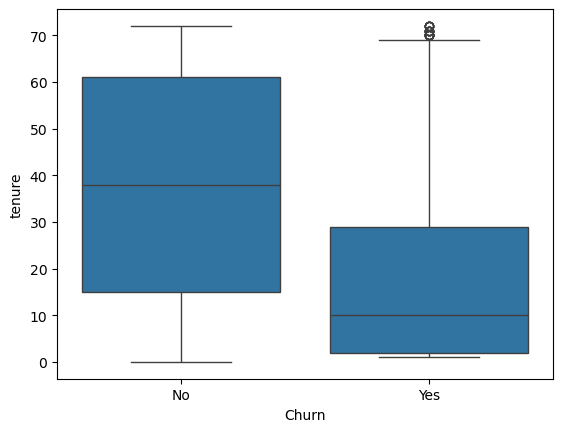

In [18]:
sns.boxplot(x='Churn', y=df['tenure'], data=df)

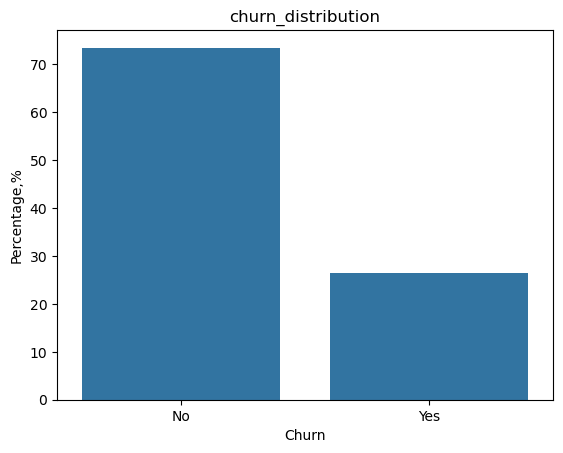

In [19]:
plot_1=sns.countplot(x='Churn', data=df, stat='percent')
plot_1.set_ylabel('Percentage,%')
plot_1.set_title('churn_distribution')
plt.show()

According to that chart we can see the unequal distribution of churn classes
Due to the fact that there are just more month-to-month contract type customers we have to represent the percentage of churn rates for each group

Text(0.5, 1.0, 'Churn Rate by Contract Types')

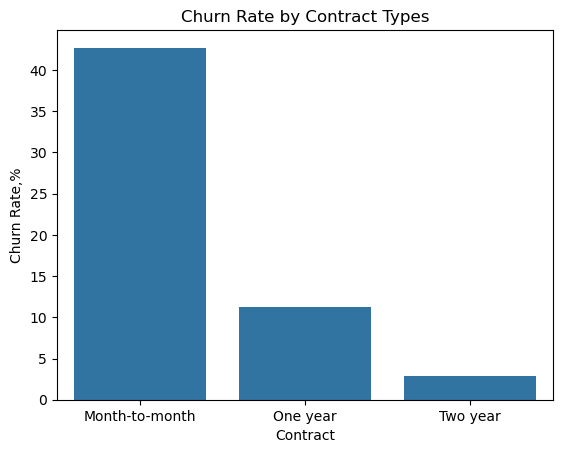

In [20]:
total_by_contract = df.groupby('Contract')['Churn'].count()
churned_by_contract = df[df['Churn'] == 'Yes'].groupby('Contract')['Churn'].count()

churn_rate_by_contract = (churned_by_contract / total_by_contract * 100)
sns.barplot(x=churn_rate_by_contract.index, y=churn_rate_by_contract.values, order=churn_rate_by_contract.sort_values(ascending=False).index)
plt.ylabel('Churn Rate,%')
plt.title('Churn Rate by Contract Types')

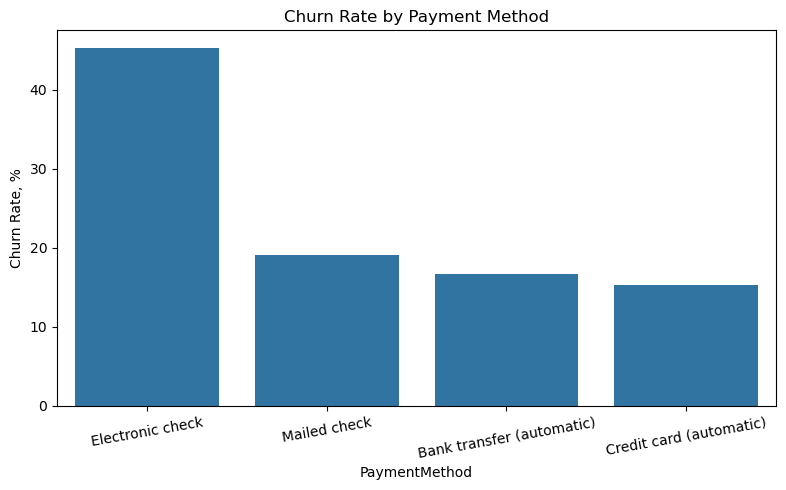

In [21]:
total_by_pmnt = df.groupby('PaymentMethod')['Churn'].count()
churned_by_pmnt = df[df['Churn'] == 'Yes'].groupby('PaymentMethod')['Churn'].count()

churn_rate_by_pmnt = (churned_by_pmnt / total_by_pmnt * 100)
plt.figure(figsize=(8, 5))
sns.barplot(x=churn_rate_by_pmnt.index, y=churn_rate_by_pmnt.values,
            order=churn_rate_by_pmnt.sort_values(ascending=False).index)
plt.ylabel('Churn Rate, %')
plt.title('Churn Rate by Payment Method')
plt.xticks(rotation=10, ha='center')
plt.tight_layout()
plt.show()

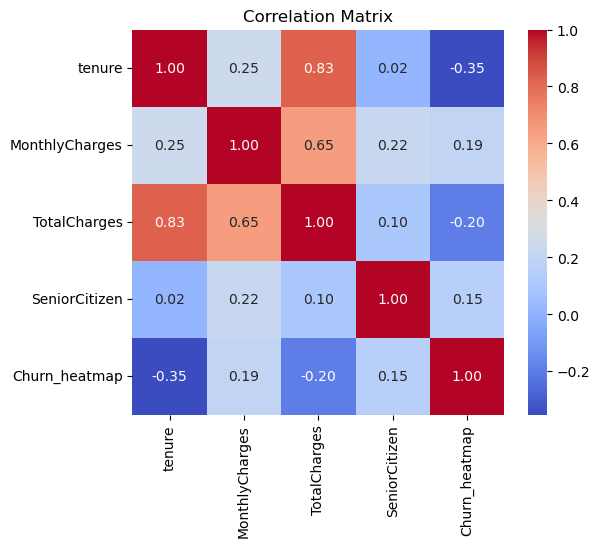

In [22]:
df['Churn_heatmap']= (df['Churn'] == 'Yes')
plt.figure(figsize=(6, 5))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn_heatmap']].corr(),annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()
#the heatmap shows the relationships between the numeric variables. the categorical variables (Internet Serivice, Payment Method and etc.) will be tested separately


The key findings for the third part:
1. Significant disbalance in classes (73% non-churned vs 23% churned)
2. Churned customers have significantly lower tenure on average (as it was said in the part 2), although some 4+years customers churn too (according to the boxplot)
3. The results actually prove the findings from the second part

**Part 4: Statistical Testing**

In [23]:
from scipy import stats

tenure_churned = df[df['Churn'] == 'Yes']['tenure']
tenure_not_churned = df[df['Churn'] == 'No']['tenure']

stat, p_value = stats.levene(tenure_churned, tenure_not_churned)
print(stat, p_value)

417.1696228201477 3.963539602787529e-90


#Levene's test checks equality of variances before choosing between Student's and Welch's t-test.

In [24]:
t_stat, t_pvalue = stats.ttest_ind(tenure_churned, tenure_not_churned, equal_var=False)
print('Welch t_test:', t_stat, t_pvalue)

Welch t_test: -34.823818696312976 1.1954945472607151e-232


In [25]:
from scipy import stats

monthly_churned = df[df['Churn'] == 'Yes']['MonthlyCharges']
monthly_not_churned = df[df['Churn'] == 'No']['MonthlyCharges']

stat, t_pvalue = stats.levene(monthly_churned, monthly_not_churned)
print(stat, t_pvalue)

361.8444859598828 1.0261244899421871e-78


In [26]:
t_stat, t_p = stats.ttest_ind(monthly_churned, monthly_not_churned, equal_var=False)
print('Welch t_test:', t_stat, t_p)

Welch t_test: 18.407526676414673 8.59244933154705e-73


In [27]:
#same here: according to the levene's test the variances were unqequal so we welch's test was used here too

In [28]:
#now we have to check association between the main categorical variables by using a chisquare test
contract_table = pd.crosstab(df['Contract'], df['Churn'])
contract_table

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [29]:
chi2_contract, p_contract, dof_contract, expected_contract = stats.chi2_contingency(contract_table)
chi2_contract, p_contract

(np.float64(1184.5965720837926), np.float64(5.863038300673393e-258))

In [30]:
payment_table = pd.crosstab(df['PaymentMethod'], df['Churn'])
payment_table

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


In [31]:
chi2_payment, p_payment, dof_payment, expected_payment = stats.chi2_contingency(payment_table)
chi2_payment, p_payment

(np.float64(648.1423274814), np.float64(3.6823546520098007e-140))

The key findings in the 4th part:
1. tenure and monthly charges differ significantly between churn/non-churn customers
2. contract and payment methods are strongly associated with churn (p-value is lower 0.01 in the both cases) 

**Part 5: Modelling (Logistic Regression)**

In [32]:
df_model = df.drop(['customerID', 'Churn_heatmap'], axis=1)

In [33]:
#now to create models we have to turn the three types of 'services' into two (binary variable)
company_services=['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
df_model[company_services] = df_model[company_services].replace({'No internet service': 'No', 'No phone service': 'No'})

In [34]:
df_model['Churn'] = (df_model['Churn'] == 'Yes').astype(int)

df_encoded = pd.get_dummies(df_model, drop_first=True, dtype=int)
#we turn some of the bariables into one-hot encoding categorical variables to avoid the multicollinearity
#moreover in order to avoid 'bool/int' mixing errors we turn all the variables of the df_model into into int type 

In [35]:
x=df_encoded.drop('Churn', axis=1)
y=df_encoded['Churn'] 
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=23)
#stratify=y` preserves the ~73/27 churn ratio in both train and test splits, given the class imbalance identified earlier

In [36]:
import statsmodels.api as sm
x_train_const = sm.add_constant(x_train)
logit_model = sm.Logit(y_train, x_train_const)
result = logit_model.fit()
print(result.summary()) 
#before trusting the results we may assume that some of the variables are correlated with each other

Optimization terminated successfully.
         Current function value: 0.411249
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 5634
Model:                          Logit   Df Residuals:                     5610
Method:                           MLE   Df Model:                           23
Date:                Mon, 21 Sep 2026   Pseudo R-squ.:                  0.2892
Time:                        13:18:12   Log-Likelihood:                -2317.0
converged:                       True   LL-Null:                       -3259.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                     1.6703      

In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['feature'] = x_train_const.columns
vif_data['VIF'] = [variance_inflation_factor(x_train_const.values, i) for i in range(x_train_const.shape[1])]
vif_data.sort_values('VIF', ascending=False)

,feature,VIF
3,MonthlyCharges,871.928093
0,const,635.185809
10,InternetService_Fiber optic,150.041277
11,InternetService_No,104.991715
8,PhoneService_Yes,35.559972
17,StreamingMovies_Yes,24.241597
16,StreamingTV_Yes,24.200876
4,TotalCharges,10.759834
2,tenure,7.499695
9,MultipleLines_Yes,7.339737


After examining the model on the vif basis we can see that vif has revealed a serious multicollinearity. Monthly Charges is almost fully explained by the other predictors combined

In [38]:
x_train_fixed = x_train.drop('MonthlyCharges', axis=1)
x_test_fixed = x_test.drop('MonthlyCharges', axis=1)

x_train_fixed_const = sm.add_constant(x_train_fixed)
x_test_fixed_const = sm.add_constant(x_test_fixed)

logit_model_fixed = sm.Logit(y_train, x_train_fixed_const)
result_fixed = logit_model_fixed.fit()
print(result_fixed.summary())

Optimization terminated successfully.
         Current function value: 0.411467
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 5634
Model:                          Logit   Df Residuals:                     5611
Method:                           MLE   Df Model:                           22
Date:                Mon, 21 Sep 2026   Pseudo R-squ.:                  0.2888
Time:                        13:18:13   Log-Likelihood:                -2318.2
converged:                       True   LL-Null:                       -3259.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                            coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
const                                     0.2560      

In [39]:
#now to analyze the business effects of the model we need to understand which exactly parameters affect the churn and lower the chances of the churn rate
import numpy as np
np.exp(result_fixed.params).sort_values()

Contract_Two year                        0.244667
InternetService_No                       0.395908
Contract_One year                        0.505105
PhoneService_Yes                         0.515317
OnlineSecurity_Yes                       0.643539
TechSupport_Yes                          0.664518
OnlineBackup_Yes                         0.807313
Dependents_Yes                           0.877933
gender_Male                              0.900571
DeviceProtection_Yes                     0.927386
tenure                                   0.937471
Partner_Yes                              0.947381
TotalCharges                             1.000396
PaymentMethod_Credit card (automatic)    1.018808
PaymentMethod_Mailed check               1.067216
MultipleLines_Yes                        1.167311
StreamingTV_Yes                          1.218059
StreamingMovies_Yes                      1.231696
const                                    1.291788
SeniorCitizen                            1.316745


**Key Findings:**
1. 2-year contract has 76% lower churn odds vs monthly subscription
2. Fiber optic has about 2 times higher churn odds than DSL
3. Service such as OnlineSecurity, TechSupport and OnlineBackup each reduce significantly the churn odds, although it was not explicit in the previous model due to the multicollinearity

In [40]:
y_pred_prob = result_fixed.predict(x_test_fixed_const)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
print('ROC-AUC:', roc_auc_score(y_test, y_pred_prob))
print(classification_report(y_test, y_pred_class))
print(confusion_matrix(y_test, y_pred_class))

ROC-AUC: 0.8392131028959674
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1035
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

[[919 116]
 [169 205]]


**Final result**
Roc-Auc: 0.84, the recall is 55%
To see the full business recommendation check readme.md 

**Part 6: Business Impact**

In [41]:
from sklearn.metrics import recall_score, precision_score

rows = []
for t in [0.5, 0.4, 0.3, 0.25]:
    pred = (y_pred_prob >= t).astype(int)
    rows.append({'threshold': t, 'recall': recall_score(y_test, pred), 'precision': precision_score(y_test, pred)})
pd.DataFrame(rows).round(2)

,threshold,recall,precision
0,0.50,0.55,0.64
1,0.40,0.68,0.56
2,0.30,0.78,0.52
3,0.25,0.82,0.50


As we expected, the lower the threshold the more churners the company finds, but more customers are found by mistake. The company should choose the threshold based on the retention offer.

In [42]:
total_revenue=df['MonthlyCharges'].sum()
lost_revenue=df.loc[df['Churn']== 'Yes', 'MonthlyCharges'].sum()
share_of_monthly_revenue_lost=(lost_revenue/total_revenue).round(3)
print(share_of_monthly_revenue_lost*100,'%')

30.5 %


In [43]:
main_group = df[(df['InternetService'] == 'Fiber optic') & (df['Contract'] == 'Month-to-month')]
main_group_lost = main_group.loc[main_group['Churn'] == 'Yes', 'MonthlyCharges'].sum()
print('share of lost revenue from the group fiber optic + month-to-month subscription:', (main_group_lost / lost_revenue).round(3) *100 , '%')

share of lost revenue from the group fiber optic + month-to-month subscription: 72.2 %


So here we can see that the group of clients that had a fiber optic internet service and also a monthly subscription were the most churn prone. According to the second formula, we can see that about 72% of the lost revenue was coming from the churned clients from that group.

In [45]:
#here I would like to illustrate a scenario that shows what if the company managed to reduce the churn rate of the fiber optic + month-to-month group by 10 percentage points 
saved_customers=len(main_group) * 0.10
revenue_saved=saved_customers * main_group['MonthlyCharges'].mean() * 12
print('in such a scenario the company would retain', round(saved_customers,0), 'clients and save' , round(revenue_saved), 'currency units')

in such a scenario the company would retain 213.0 clients and save 222217 currency units


About 30% monthly revenue is lost due to the churn. The fiber optic + month-to-month group is 30% of all the clients, but it makes up 62% of the churned clients and gives about 72% of the revenue loss. If the company would try to reduce the churn rate of the group by 10 percentage points it would save about 213 clients and 220 k currency units per year. Obviously, that was just an illustrative scenario, and the real effect should be tested on a pilot group. However, it is clear that the above mentioned group of customers should be the target to retain.